### José Ignacio Valbuena - Data Science III - Comisión 102200

# PreEntrega 1 · Pipeline de clasificación con PyTorch

**Problema:** identificar la especie de una flor Iris a partir de cuatro medidas.
**Objetivo:** construir un pipeline reproducible con un MLP simple, Adam y validación separada.

El foco de esta entrega es el funcionamiento del proceso de aprendizaje. Se utiliza Iris,
una de las opciones propuestas por la consigna. Ejecutar las celdas en orden desde un kernel nuevo.

**Recorrido:** entorno → datos → preparación → modelo → entrenamiento → validación → resultados.

## 1. Entorno y reproducibilidad
Se fijan semillas y se selecciona CUDA, MPS o CPU. Las semillas favorecen la repetibilidad;
pueden persistir diferencias entre dispositivos y versiones. CPU es suficiente para este dataset.

In [1]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import json
import platform
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Markdown, Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)
torch.set_num_threads(1)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# Funciona al abrir el notebook desde la raíz o desde notebooks/.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
RESULTS = ROOT / "results"
DATA.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
print(f"Python: {platform.python_version()} | PyTorch: {torch.__version__}")
print(f"Dispositivo: {device} | Semilla: {SEED}")

Python: 3.12.14 | PyTorch: 2.15.0+cpu
Dispositivo: cpu | Semilla: 42


## 2. Carga y exploración breve
Iris contiene 150 flores, cuatro medidas en centímetros y tres especies.
Cada fila es una flor; la etiqueta es la especie. La carga desde scikit-learn no requiere descargar datos.

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
class_names = list(iris.target_names)
display(df.head())
display(df.describe().round(2))
print("Dimensiones:", df.shape)
print("Valores faltantes:", int(df.isna().sum().sum()))
print("Filas duplicadas completas:", int(df.duplicated().sum()))
display(df["target"].value_counts().sort_index().rename(index=dict(enumerate(class_names))))

# Se guarda una copia para inspección y trazabilidad.
df.to_csv(DATA / "iris.csv", index=False)
assert df.isna().sum().sum() == 0

Dimensiones: (150, 5)
Valores faltantes: 0
Filas duplicadas completas: 1


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.00,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20,1.00
std,0.83,0.44,1.77,0.76,0.82
min,4.30,2.00,1.00,0.10,0.00
25%,5.10,2.80,1.60,0.30,0.00
50%,5.80,3.00,4.35,1.30,1.00
75%,6.40,3.30,5.10,1.80,2.00
max,7.90,4.40,6.90,2.50,2.00


target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

**Lectura del dataset:** las clases tienen la misma cantidad de ejemplos. Las variables son numéricas,
pero tienen escalas distintas. Una fila con medidas idénticas a otra no demuestra que sea la misma flor;
se conserva el dataset de referencia y se documenta esta limitación. No se utilizan identificadores como entradas.

## 3. División y estandarización sin filtración
Se reserva 20 % para validación y 80 % para entrenamiento, con estratificación por especie.
El estandarizador aprende media y desviación **solo de entrenamiento** y luego transforma ambos conjuntos.
La validación sirve para monitoreo; no es un conjunto de prueba final independiente.

In [3]:
X = iris.data.to_numpy(dtype=np.float32)
y = iris.target.to_numpy(dtype=np.int64)
indices = np.arange(len(y))
train_idx, val_idx = train_test_split(
    indices, test_size=0.20, stratify=y, random_state=SEED
)
X_train, X_val = X[train_idx], X[val_idx]
y_train, y_val = y[train_idx], y[val_idx]

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)

assert set(train_idx).isdisjoint(set(val_idx))
assert len(train_idx) + len(val_idx) == len(y)
print(f"Entrenamiento: {len(y_train)} | Validación: {len(y_val)}")
display(pd.DataFrame({
    "especie": class_names,
    "entrenamiento": np.bincount(y_train, minlength=3),
    "validacion": np.bincount(y_val, minlength=3),
}))

# Se guardan los índices y parámetros para reproducir la preparación.
preparation = {
    "seed": SEED, "train_indices": train_idx.tolist(), "val_indices": val_idx.tolist(),
    "feature_names": list(iris.feature_names), "class_names": class_names,
    "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist(),
}
(RESULTS / "preparacion.json").write_text(json.dumps(preparation, indent=2), encoding="utf-8")

Entrenamiento: 120 | Validación: 30


,especie,entrenamiento,validacion
0,setosa,40,10
1,versicolor,40,10
2,virginica,40,10


## 4. Tensores y lotes
Las entradas usan `float32` y las etiquetas `int64`, como requiere `CrossEntropyLoss`.
Solo el cargador de entrenamiento mezcla los ejemplos. Cada lote se enviará al dispositivo del modelo.

In [4]:
BATCH_SIZE = 16
train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
val_ds = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val))
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=generator, num_workers=0
)
train_eval_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=False)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
print("Entradas:", train_ds.tensors[0].shape, train_ds.tensors[0].dtype)
print("Etiquetas:", train_ds.tensors[1].shape, train_ds.tensors[1].dtype)

Entradas: torch.Size([120, 4]) torch.float32
Etiquetas: torch.Size([120]) torch.int64


## 5. Arquitectura, pérdida y optimizador
MLP: **4 entradas → 8 neuronas con ReLU → 3 salidas**. ReLU introduce no linealidad.
Las salidas son logits: `CrossEntropyLoss` incorpora el cálculo necesario sin aplicar Softmax previamente.
Adam actualiza los pesos; `learning_rate=0.01` es una elección inicial fija para esta prueba pequeña.
Se entrenan 100 épocas y se reporta la última, sin escoger la de mejor validación.

In [5]:
class IrisMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(4, 8),
            nn.ReLU(),
            nn.Linear(8, 3),
        )

    def forward(self, x):
        return self.network(x)

LEARNING_RATE = 0.01
EPOCHS = 100
model = IrisMLP().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(model)
print("Parámetros entrenables:", sum(p.numel() for p in model.parameters() if p.requires_grad))
with torch.no_grad():
    output_shape = model(train_ds.tensors[0][:5].to(device)).shape
assert output_shape == (5, 3)
print("Salida para 5 flores:", output_shape)

IrisMLP(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=3, bias=True)
  )
)
Parámetros entrenables: 67
Salida para 5 flores: torch.Size([5, 3])


## 6. Funciones de entrenamiento y validación
Entrenar implica limpiar gradientes, predecir, calcular la pérdida, retropropagar y actualizar con Adam.
Evaluar utiliza `eval()` y `no_grad()`: no actualiza pesos ni acumula gradientes.
La pérdida promedio se pondera por cantidad de ejemplos, incluyendo el último lote incompleto.

In [6]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    for inputs, targets in loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()            # Reiniciar gradientes.
        logits = model(inputs)           # Forward.
        loss = criterion(logits, targets)
        loss.backward()                  # Autograd: calcular gradientes.
        optimizer.step()                 # Adam: actualizar pesos.

        total_samples += targets.size(0)
        total_loss += loss.item() * targets.size(0)
        total_correct += (logits.argmax(dim=1) == targets).sum().item()
    return total_loss / total_samples, total_correct / total_samples


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            logits = model(inputs)
            loss = criterion(logits, targets)
            total_samples += targets.size(0)
            total_loss += loss.item() * targets.size(0)
            total_correct += (logits.argmax(dim=1) == targets).sum().item()
    return total_loss / total_samples, total_correct / total_samples

## 7. Ejecución y registro por época
Se registran pérdida y Accuracy en ambos conjuntos. Las métricas de entrenamiento se vuelven a
calcular al finalizar cada época para compararlas con validación usando los mismos pesos.

In [7]:
initial_train_loss, initial_train_acc = evaluate(model, train_eval_loader, criterion, device)
initial_val_loss, initial_val_acc = evaluate(model, val_loader, criterion, device)
initial_weights = [p.detach().clone() for p in model.parameters()]
history = []

for epoch in range(1, EPOCHS + 1):
    online_loss, _ = train_one_epoch(model, train_loader, criterion, optimizer, device)
    train_loss, train_acc = evaluate(model, train_eval_loader, criterion, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    history.append({
        "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
        "train_accuracy": train_acc, "val_accuracy": val_acc,
        "online_train_loss": online_loss,
    })
    if epoch == 1 or epoch % 20 == 0:
        print(f"Época {epoch:3d} | loss train {train_loss:.4f} | loss val {val_loss:.4f} | "
              f"Accuracy train {train_acc:.2%} | Accuracy val {val_acc:.2%}")

history_df = pd.DataFrame(history)
history_df.to_csv(RESULTS / "historial.csv", index=False)
display(history_df.tail())

Época   1 | loss train 0.9543 | loss val 0.9662 | Accuracy train 80.83% | Accuracy val 80.00%
Época  20 | loss train 0.1004 | loss val 0.1463 | Accuracy train 96.67% | Accuracy val 93.33%
Época  40 | loss train 0.0553 | loss val 0.0903 | Accuracy train 98.33% | Accuracy val 93.33%
Época  60 | loss train 0.0463 | loss val 0.0757 | Accuracy train 98.33% | Accuracy val 96.67%
Época  80 | loss train 0.0425 | loss val 0.0691 | Accuracy train 98.33% | Accuracy val 96.67%
Época 100 | loss train 0.0401 | loss val 0.0663 | Accuracy train 98.33% | Accuracy val 96.67%


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,online_train_loss
95,96,0.040801,0.067883,0.983333,0.966667,0.041344
96,97,0.040407,0.066475,0.983333,0.966667,0.042399
97,98,0.040422,0.066462,0.983333,0.966667,0.042238
98,99,0.040413,0.065873,0.983333,0.966667,0.041772
99,100,0.040140,0.066311,0.983333,0.966667,0.040656


## 8. Curvas de aprendizaje
Una pérdida menor indica mejor ajuste según la función objetivo. Accuracy es la proporción de aciertos.
Si la pérdida de entrenamiento baja mientras la de validación sube de manera sostenida, puede haber sobreajuste.

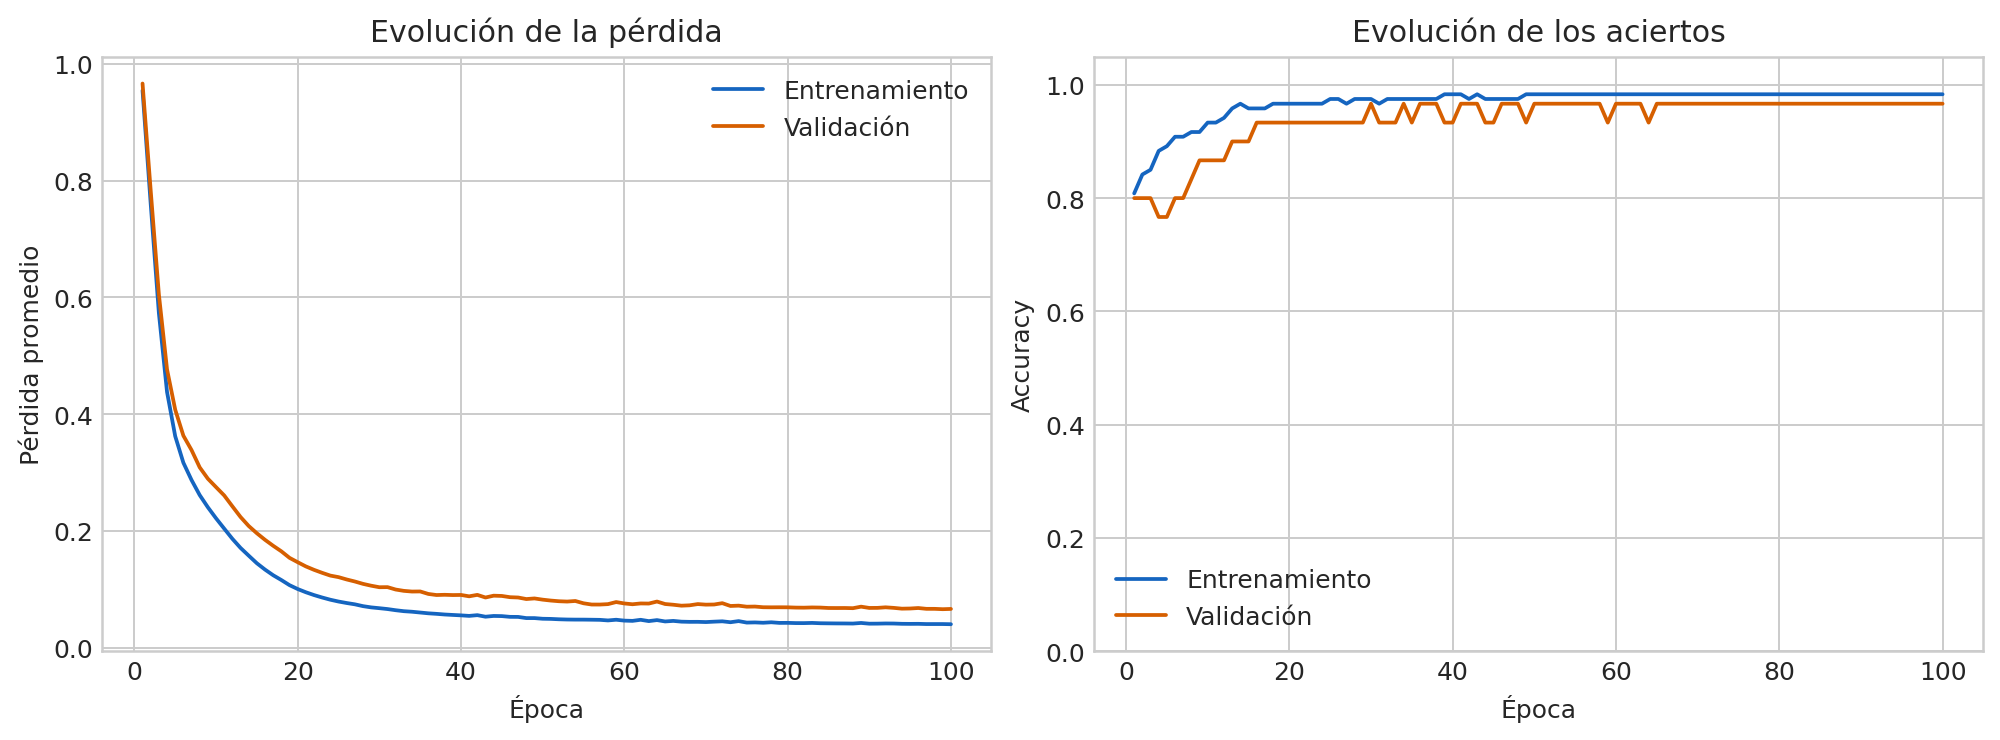

In [8]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].plot(history_df.epoch, history_df.train_loss, label="Entrenamiento", color="#1565c0")
axes[0].plot(history_df.epoch, history_df.val_loss, label="Validación", color="#d65f00")
axes[0].set(xlabel="Época", ylabel="Pérdida promedio", title="Evolución de la pérdida")
axes[1].plot(history_df.epoch, history_df.train_accuracy, label="Entrenamiento", color="#1565c0")
axes[1].plot(history_df.epoch, history_df.val_accuracy, label="Validación", color="#d65f00")
axes[1].set(xlabel="Época", ylabel="Accuracy", title="Evolución de los aciertos", ylim=(0, 1.05))
for ax in axes:
    ax.legend()
fig.savefig(RESULTS / "curvas_aprendizaje.png", dpi=180, bbox_inches="tight")
display(Image(filename=str(RESULTS / "curvas_aprendizaje.png")))
plt.close(fig)

## 9. Verificación y resultados
Se comprueba que las métricas sean válidas, que los pesos hayan cambiado y que evaluar no los modifique.
La tabla compara el modelo sin entrenar con el de la última época.

In [9]:
assert len(history_df) == EPOCHS
assert np.isfinite(history_df.to_numpy()).all()
assert history_df[["train_accuracy", "val_accuracy"]].ge(0).all().all()
assert history_df[["train_accuracy", "val_accuracy"]].le(1).all().all()
assert any(not torch.equal(before, after) for before, after in zip(initial_weights, model.parameters()))
before_eval = [p.detach().clone() for p in model.parameters()]
final_val_loss, final_val_acc = evaluate(model, val_loader, criterion, device)
assert all(torch.equal(before, after) for before, after in zip(before_eval, model.parameters()))

last = history_df.iloc[-1]
summary = pd.DataFrame([
    {"momento": "Antes de entrenar", "train_loss": initial_train_loss,
     "val_loss": initial_val_loss, "train_accuracy": initial_train_acc, "val_accuracy": initial_val_acc},
    {"momento": "Última época", "train_loss": last.train_loss,
     "val_loss": final_val_loss, "train_accuracy": last.train_accuracy, "val_accuracy": final_val_acc},
]).set_index("momento")
display(summary.round(4))
summary.to_csv(RESULTS / "resumen.csv")

metrics = {
    "author": "José Ignacio Valbuena", "course": "Data Science III", "commission": "102200",
    "python": platform.python_version(), "torch": torch.__version__, "sklearn": sklearn.__version__,
    "device": str(device), "seed": SEED, "learning_rate": LEARNING_RATE,
    "epochs": EPOCHS, "batch_size": BATCH_SIZE, "train_size": len(y_train), "val_size": len(y_val),
    "initial_train_loss": initial_train_loss, "initial_val_loss": initial_val_loss,
    "final_train_loss": float(last.train_loss), "final_val_loss": final_val_loss,
    "final_train_accuracy": float(last.train_accuracy), "final_val_accuracy": final_val_acc,
}
(RESULTS / "experimento.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print("Verificación correcta: épocas completas, métricas finitas, aprendizaje y validación sin actualizar pesos.")

Verificación correcta: épocas completas, métricas finitas, aprendizaje y validación sin actualizar pesos.


,train_loss,val_loss,train_accuracy,val_accuracy
momento,,,,
Antes de entrenar,1.1529,1.1489,0.0500,0.0667
Última época,0.0401,0.0663,0.9833,0.9667


In [10]:
display(Markdown(
    f"**Conclusión del experimento.** La pérdida de entrenamiento pasó de "
    f"{initial_train_loss:.4f} a {last.train_loss:.4f}, y la de validación de "
    f"{initial_val_loss:.4f} a {final_val_loss:.4f}. El Accuracy final fue "
    f"{last.train_accuracy:.1%} en entrenamiento y {final_val_acc:.1%} en validación. "
    f"La diferencia de Accuracy fue de {100 * (last.train_accuracy - final_val_acc):.1f} puntos porcentuales."
))

**Conclusión del experimento.** La pérdida de entrenamiento pasó de 1.1529 a 0.0401, y la de validación de 1.1489 a 0.0663. El Accuracy final fue 98.3% en entrenamiento y 96.7% en validación. La diferencia de Accuracy fue de 1.7 puntos porcentuales.

**Interpretación de las curvas obtenidas:** ambas pérdidas disminuyen y se estabilizan en valores bajos. La validación se mantiene próxima al entrenamiento; no se observa una subida sostenida de su pérdida que sugiera sobreajuste marcado en esta ejecución. El Accuracy de validación presenta pequeños saltos por el tamaño reducido del conjunto.

**Limitaciones:** la validación incluye solo 30 flores: cada error cambia el Accuracy en aproximadamente
3,33 puntos porcentuales. Una partición y una semilla no permiten estimar toda la variabilidad.
Las curvas deben interpretarse completas; una oscilación aislada no demuestra sobreajuste.
Las medidas repetidas y la naturaleza educativa del dataset limitan la extrapolación.

**Mejoras futuras:** repetir con varias semillas o validación cruzada y reservar un conjunto de prueba
independiente si se ajustan hiperparámetros. El objetivo actual es verificar el pipeline base.

## 10. Control de entrega

| Criterio | Peso | Evidencia |
|---|---:|---|
| Estructura profesional | 20 % | Notebook organizado, carpetas, README y requirements |
| Entorno y dispositivo | 15 % | Sección 1; semillas y selección automática |
| Arquitectura base | 15 % | Sección 5; nn.Module, 4 → 8 → 3 |
| Entrenamiento con autograd y Adam | 35 % | Secciones 6 y 7; backward y step explícitos |
| Validación | 10 % | evaluate separada, loss y Accuracy por época |
| Documentación | 5 % | README con versión, learning rate y resultados |

**Entrega en plataforma:** subir el contenido del paquete a un repositorio GitHub/GitLab y entregar su enlace.
El paquete no publica automáticamente el repositorio. Utilizar commits descriptivos.
El 70 % de aprobación se refiere a la rúbrica, no al Accuracy exigido al modelo.

**Fuentes:** consigna “Pre Entrega 1” y material “Data Science III”, módulo 1, especialmente
las secciones de PyTorch, autograd, Adam y el checkpoint. Datos: Iris, distribuido con scikit-learn;
información de procedencia disponible en `load_iris().DESCR`.